# Activity 3
John Rendell B. Tapire
CPE4A

Input: `coins.png` 
The reference uses RGB thresholds → channel intersection → inversion → hole filling →
morphological opening → connected components → bounding boxes. This implementation
keeps that sequence, adapts the thresholds to the white background, and filters noise
using relative area and shape. It counts coins without assigning denominations from
pixel area: the supplied coins include different sizes and designs.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Support a kernel started in either this activity folder or the project root.
activity_dir = Path.cwd()
if not (activity_dir / 'images').is_dir():
    activity_dir = activity_dir / 'Activity_03'
image_dir = activity_dir / 'images'
if not image_dir.is_dir():
    raise FileNotFoundError('Open the project root or this activity folder in VS Code.')

def show_stages(stages, columns=3):
    rows = (len(stages) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 3.6 * rows), squeeze=False)
    for axis, (title, picture) in zip(axes.flat, stages):
        axis.imshow(picture, cmap='gray' if picture.ndim == 2 else None)
        axis.set_title(title)
    for axis in axes.flat:
        axis.axis('off')
    plt.tight_layout()
    plt.show()

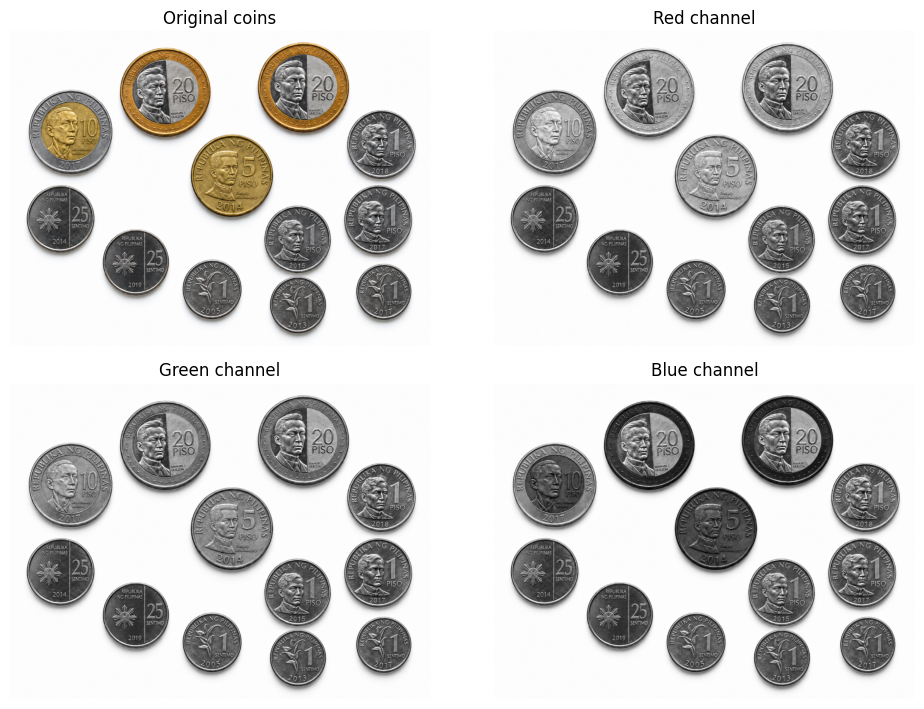

In [2]:
# 1. Read the user's image and keep the original proportions.
image = cv2.imread(str(image_dir / 'coins.png'))
if image is None:
    raise FileNotFoundError(image_dir / 'coins.png')
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
red, green, blue = cv2.split(image_rgb)
show_stages([('Original coins', image_rgb), ('Red channel', red),
             ('Green channel', green), ('Blue channel', blue)], columns=2)

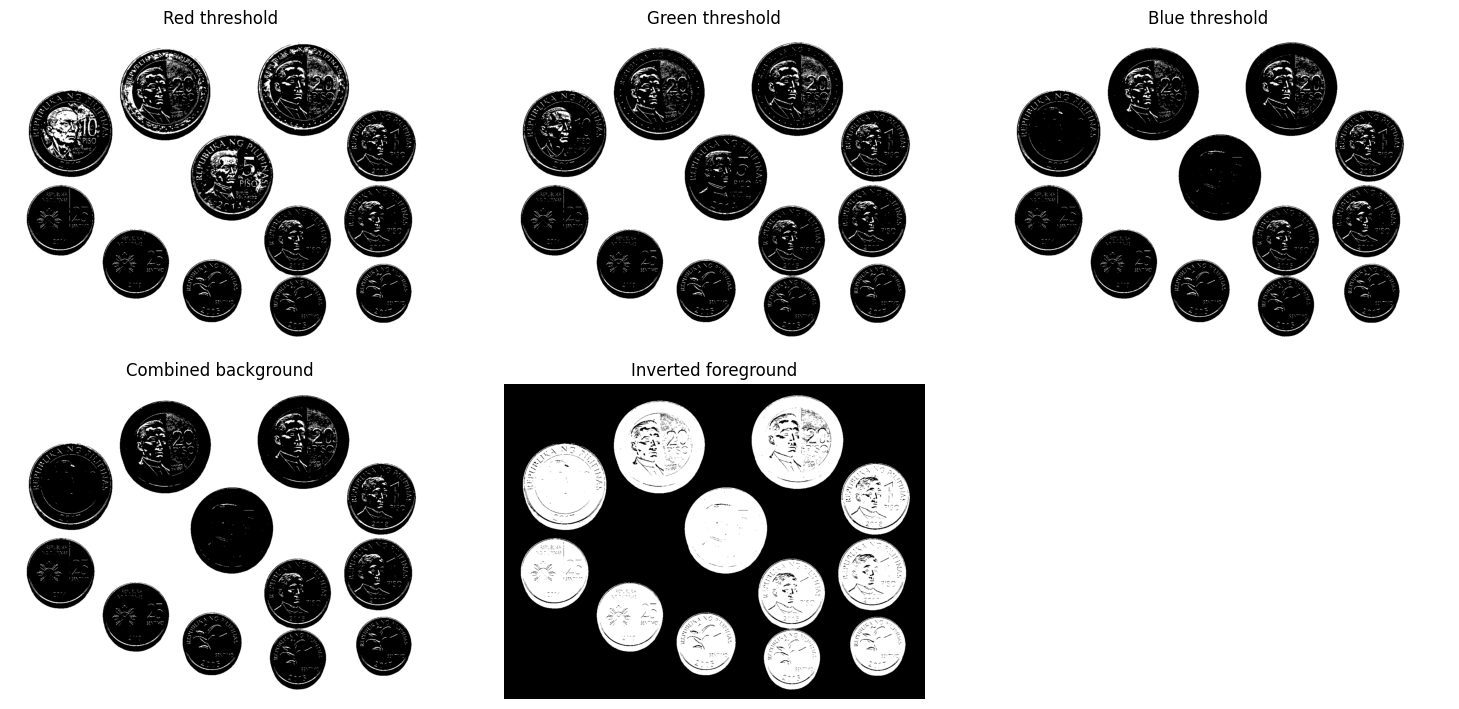

In [3]:
# 2. A pixel belongs to the bright background only when all channels exceed the cutoff.
# Invert the intersection so the coins become white foreground objects.
# A cutoff of 180 excludes the faint shadows that otherwise join two nearby coins.
background_threshold = 180
red_mask = (red > background_threshold).astype(np.uint8) * 255
green_mask = (green > background_threshold).astype(np.uint8) * 255
blue_mask = (blue > background_threshold).astype(np.uint8) * 255
background_mask = cv2.bitwise_and(cv2.bitwise_and(red_mask, green_mask), blue_mask)
coin_mask = cv2.bitwise_not(background_mask)
show_stages([('Red threshold', red_mask), ('Green threshold', green_mask),
             ('Blue threshold', blue_mask), ('Combined background', background_mask),
             ('Inverted foreground', coin_mask)])

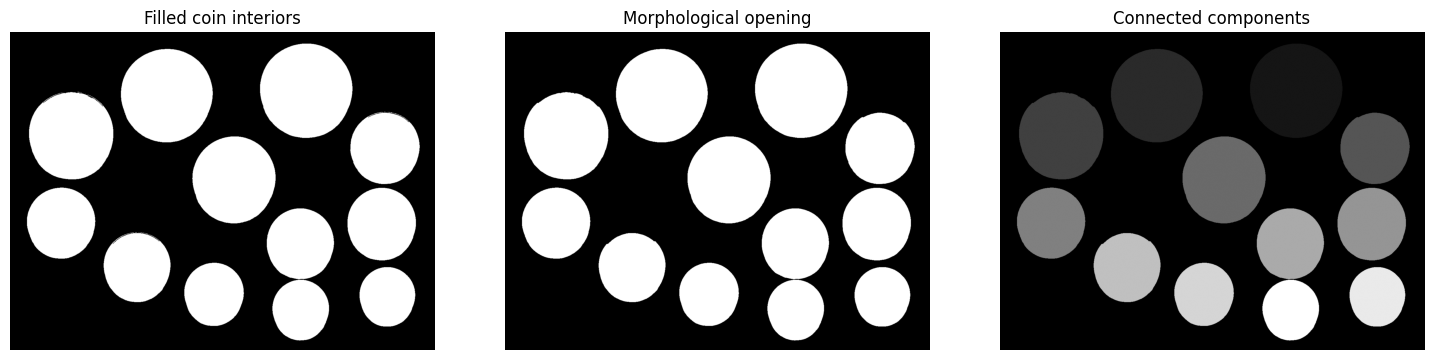

In [4]:
# 3. Pad before flood filling so the seed is guaranteed to lie outside a coin.
padded = cv2.copyMakeBorder(coin_mask, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
flooded = padded.copy()
cv2.floodFill(flooded, None, (0, 0), 255)
filled = cv2.bitwise_or(padded, cv2.bitwise_not(flooded))[1:-1, 1:-1]

# Opening removes small speckles and weak shadow connections.
radius = max(2, round(min(coin_mask.shape) * 0.005))
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * radius + 1, 2 * radius + 1))
opened = cv2.morphologyEx(filled, cv2.MORPH_OPEN, kernel)

# 4. Label foreground regions and keep substantial, approximately round objects.
label_count, labels, stats, centroids = cv2.connectedComponentsWithStats(opened, connectivity=8)
minimum_area = opened.size * 0.008
objects = []
for label_id in range(1, label_count):  # label 0 is the background
    x, y, width, height, area = stats[label_id]
    aspect_ratio = width / height
    if area >= minimum_area and 0.65 <= aspect_ratio <= 1.4:
        objects.append((x, y, width, height, area))
objects.sort(key=lambda item: (item[1], item[0]))
show_stages([('Filled coin interiors', filled), ('Morphological opening', opened),
             ('Connected components', labels)])

Coin 1: foreground area = 79735 pixels
Coin 2: foreground area = 78196 pixels
Coin 3: foreground area = 67380 pixels
Coin 4: foreground area = 45189 pixels
Coin 5: foreground area = 65907 pixels
Coin 6: foreground area = 44227 pixels
Coin 7: foreground area = 45488 pixels
Coin 8: foreground area = 43456 pixels
Coin 9: foreground area = 42098 pixels
Coin 10: foreground area = 34314 pixels
Coin 11: foreground area = 30240 pixels
Coin 12: foreground area = 31237 pixels


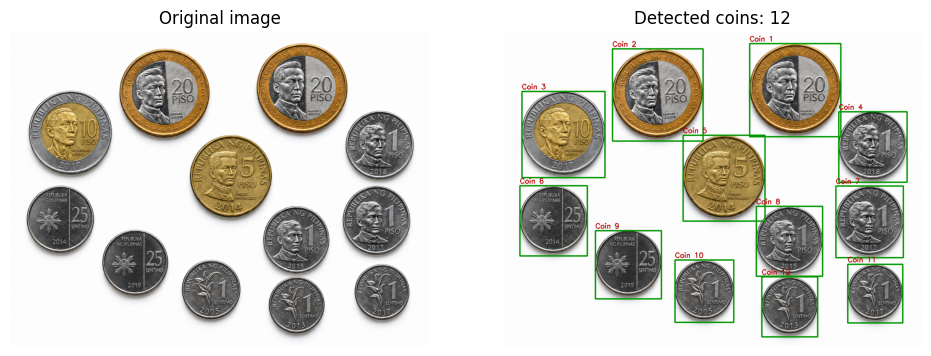

Total object count: 12


In [5]:
# 5. Draw one box per detected connected component; calculate the count from the list.
result = image_rgb.copy()
for number, (x, y, width, height, area) in enumerate(objects, start=1):
    cv2.rectangle(result, (x, y), (x + width, y + height), (0, 150, 0), 3)
    cv2.putText(result, f'Coin {number}', (x, max(25, y - 8)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (180, 0, 0), 2)
    print(f'Coin {number}: foreground area = {area} pixels')
total_count = len(objects)
show_stages([('Original image', image_rgb), (f'Detected coins: {total_count}', result)], columns=2)
print(f'Total object count: {total_count}')

The count is computed from image regions, never a fixed number. This approach assumes
separated coins on a bright background. Touching coins can merge into one region;
changing illumination may require adjusting `background_threshold` and the filters.